In [1]:
%load_ext autoreload
%autoreload 2
import os, sys
import itertools
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from scipy.optimize import brentq
from IPython.display import Image, display

In [4]:
# Output directories for results and plots
outputs_dir = os.path.join(os.getcwd(), 'outputs')
os.makedirs(outputs_dir, exist_ok=True)
OUT = Path(outputs_dir) / 'figure6_signal_manip_outputs'
OUT.mkdir(parents=True, exist_ok=True)

plots_dir = os.path.join(os.getcwd(), "plots")
os.makedirs(plots_dir, exist_ok=True)

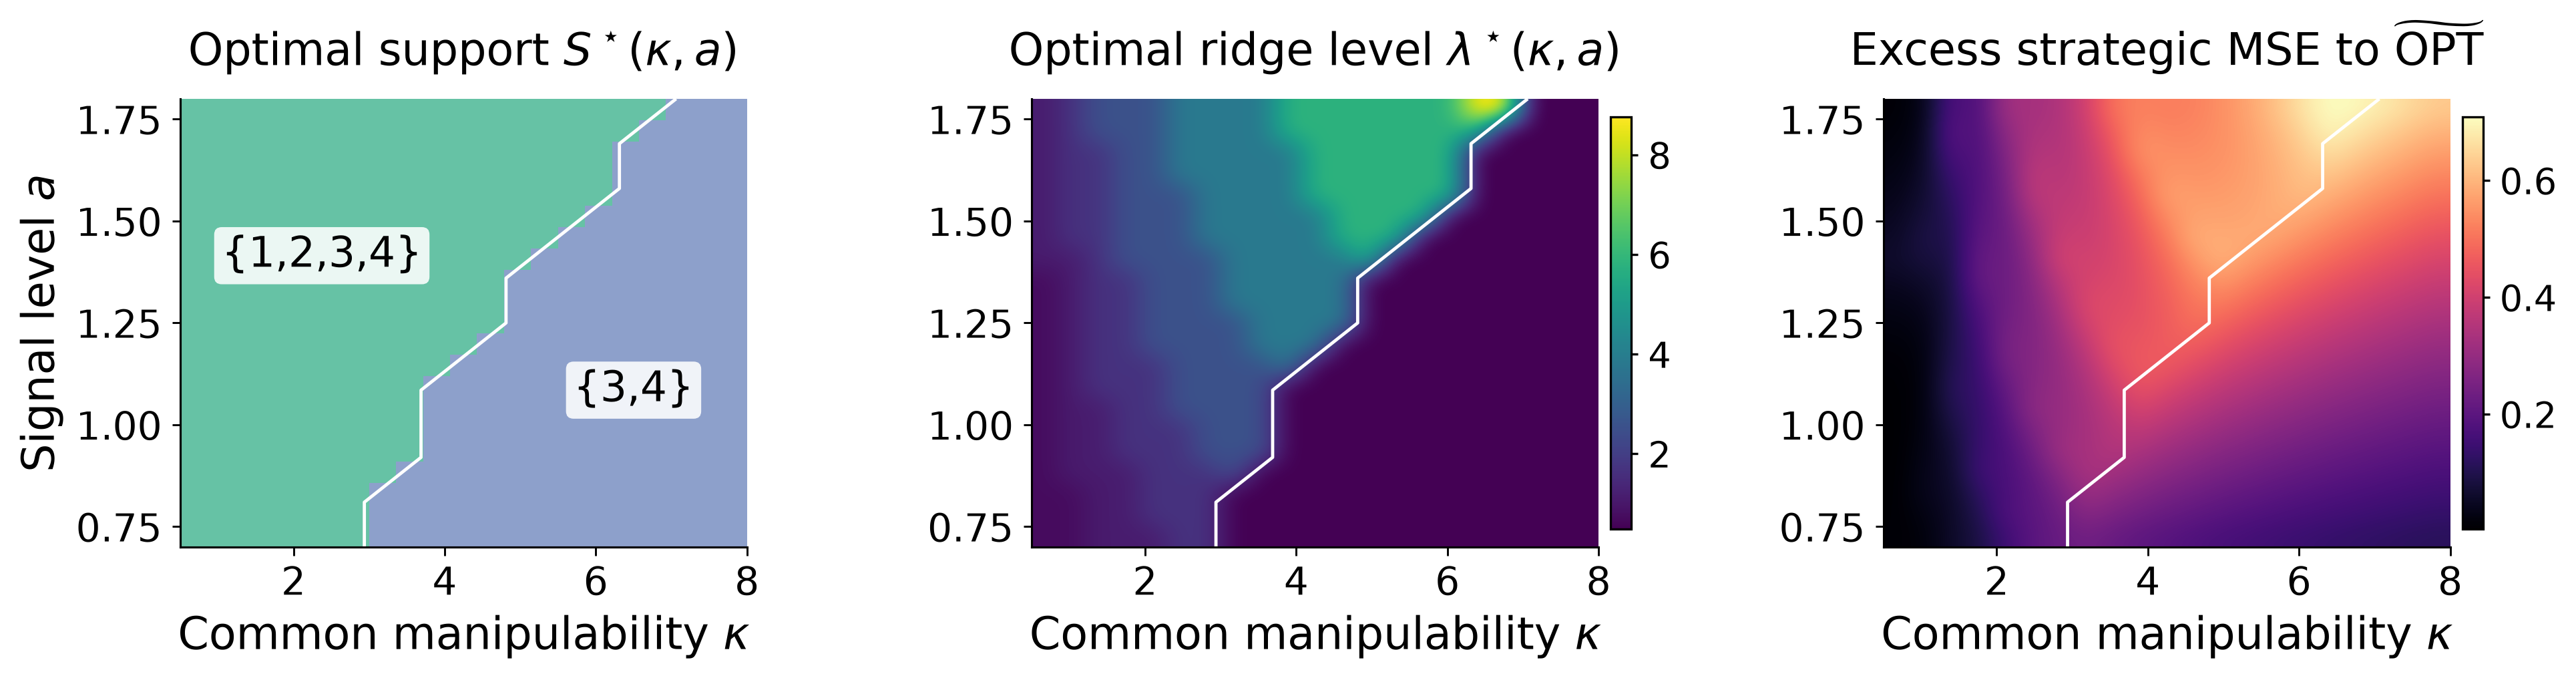

In [5]:
# Plotting setup
plt.rcParams.update({
    'font.size': 15.0,
    'axes.labelsize': 16.0,
    'axes.titlesize': 16.0,
    'xtick.labelsize': 14.0,
    'ytick.labelsize': 14.0,
    'legend.fontsize': 14.0,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'figure.dpi': 240,
    'savefig.dpi': 300,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})

LAMBDA_GRID = np.concatenate(([0.0], np.geomspace(1e-3, 20.0, 25)))

# Core functions
def strategic_mse(theta, Sigma, K, theta_star):
    diff = theta - theta_star
    return float(diff @ Sigma @ diff + (theta @ K @ theta) ** 2)

def support_to_text(S):
    return '{' + ','.join(str(i + 1) for i in S) + '}' if len(S) else r'$\emptyset$'

def subset_ridge_theta(S, lam, Sigma, theta_star):
    d = len(theta_star)
    theta = np.zeros(d)
    S = list(S)
    if len(S) == 0:
        return theta
    SS = Sigma[np.ix_(S, S)]
    Sy = Sigma[np.ix_(S, range(d))] @ theta_star
    theta[S] = np.linalg.solve(SS + lam * np.eye(len(S)), Sy)
    return theta

def best_subset_from_lambda_grid(Sigma, K, theta_star):
    d = len(theta_star)
    best = None
    for r in range(d + 1):
        for S in itertools.combinations(range(d), r):
            vals = [strategic_mse(subset_ridge_theta(S, lam, Sigma, theta_star), Sigma, K, theta_star)
                    for lam in LAMBDA_GRID]
            i = int(np.argmin(vals))
            row = {
                'support_text': support_to_text(S),
                'lambda_star': float(LAMBDA_GRID[i]),
                'risk_star': float(vals[i]),
            }
            if best is None or row['risk_star'] < best['risk_star'] - 1e-12:
                best = row
    return best

def full_zero_intercept_oracle(Sigma, K, theta_star):
    rhs = Sigma @ theta_star
    q0 = float(theta_star @ K @ theta_star)

    def theta_of_q(q):
        return np.linalg.solve(Sigma + 2.0 * q * K, rhs)

    def fixed_point(q):
        th = theta_of_q(q)
        return float(th @ K @ th - q)

    hi = max(1.0, q0)
    while fixed_point(hi) > 0:
        hi *= 2.0
    q_star = brentq(fixed_point, 0.0, hi, xtol=1e-12, rtol=1e-10, maxiter=100)
    theta = theta_of_q(q_star)
    diff = theta - theta_star
    return float(diff @ Sigma @ diff + (theta @ K @ theta) ** 2)

def region_centers(df, xcol, ycol, scol):
    return {s: (float(sub[xcol].median()), float(sub[ycol].median())) for s, sub in df.groupby(scol)}

def prettify(ax):
    ax.tick_params(length=3.0, width=0.7)
    for spine in ax.spines.values():
        spine.set_linewidth(0.75)

# Problem setup
Sigma = np.eye(4)
a_grid = np.linspace(0.7, 1.8, 21)
kappa_grid = np.linspace(0.5, 8.0, 21)
rows = []
for a in a_grid:
    theta_star = np.array([a, a, 1.0, 0.9], float)
    for kappa in kappa_grid:
        K = np.diag([kappa, kappa, 0.6, 0.6])
        best = best_subset_from_lambda_grid(Sigma, K, theta_star)
        oracle_val = full_zero_intercept_oracle(Sigma, K, theta_star)
        rows.append({
            'a': a,
            'kappa': kappa,
            'support_text': best['support_text'],
            'lambda_star': best['lambda_star'],
            'total_gap': best['risk_star'] - oracle_val
        })

df = pd.DataFrame(rows)
df.to_csv(OUT / 'signal_manip_data.csv', index=False)

support_order = [s for s in ['{3,4}', '{1,2,3,4}'] if s in set(df['support_text'])]
support_map = {s: i for i, s in enumerate(support_order)}
cmap = ListedColormap(['#8da0cb', '#66c2a5'][:len(support_order)])
norm = BoundaryNorm(np.arange(-0.5, len(support_order) + 0.5, 1), cmap.N)
A = np.sort(df['a'].unique())
K_vals = np.sort(df['kappa'].unique())
support_grid = df.assign(code=df['support_text'].map(support_map)).pivot(index='a', columns='kappa', values='code').loc[A, K_vals].values
lambda_grid = df.pivot(index='a', columns='kappa', values='lambda_star').loc[A, K_vals].values
gap_grid = df.pivot(index='a', columns='kappa', values='total_gap').loc[A, K_vals].values

fig, axs = plt.subplots(1, 3, figsize=(12.8, 3.55), constrained_layout=False)
fig.subplots_adjust(left=0.055, right=0.985, top=0.85, bottom=0.22, wspace=0.25)

ax = axs[0]
im0 = ax.imshow(support_grid, origin='lower', aspect='auto', interpolation='nearest',
          extent=[K_vals.min(), K_vals.max(), A.min(), A.max()], cmap=cmap, norm=norm)
if len(support_order) > 1:
    ax.contour(K_vals, A, support_grid, levels=[0.5], colors='white', linewidths=1.15)
ax.set_title(r'Optimal support $S^\star(\kappa,a)$', loc='center', pad=12)
ax.set_xlabel(r'Common manipulability $\kappa$')
ax.set_ylabel(r'Signal level $a$')

centers = region_centers(df, 'kappa', 'a', 'support_text')
for s in support_order:
    if s in centers:
        ax.text(*centers[s], s, ha='center', va='center', fontsize=15.0,
                bbox=dict(boxstyle='round,pad=0.18', facecolor='white', edgecolor='none', alpha=0.88))

# Invisible colorbar trick
cb0 = fig.colorbar(im0, ax=ax, shrink=0.92, pad=0.018)
cb0.ax.set_visible(False)
prettify(ax)

ax = axs[1]
im1 = ax.imshow(lambda_grid, origin='lower', aspect='auto', interpolation='bicubic',
               extent=[K_vals.min(), K_vals.max(), A.min(), A.max()], cmap='viridis')
if len(support_order) > 1:
    ax.contour(K_vals, A, support_grid, levels=[0.5], colors='white', linewidths=1.15)
ax.set_title(r'Optimal ridge level $\lambda^\star(\kappa,a)$', loc='center', pad=12)
ax.set_xlabel(r'Common manipulability $\kappa$')

cb1 = fig.colorbar(im1, ax=ax, shrink=0.92, pad=0.018)
cb1.ax.tick_params(labelsize=13.0, length=2.5)
prettify(ax)

ax = axs[2]
im2 = ax.imshow(gap_grid, origin='lower', aspect='auto', interpolation='bicubic',
                extent=[K_vals.min(), K_vals.max(), A.min(), A.max()], cmap='magma')
if len(support_order) > 1:
    ax.contour(K_vals, A, support_grid, levels=[0.5], colors='white', linewidths=1.15)
ax.set_title(r'Excess strategic MSE to $\widetilde{\mathrm{OPT}}$', loc='center', pad=12)
ax.set_xlabel(r'Common manipulability $\kappa$')

cb2 = fig.colorbar(im2, ax=ax, shrink=0.92, pad=0.018)
cb2.ax.tick_params(labelsize=13.0, length=2.5)
prettify(ax)

fig.savefig(os.path.join(plots_dir, 'supp_signal_manip.png'), bbox_inches='tight')
fig.savefig(os.path.join(plots_dir, 'supp_signal_manip.pdf'), bbox_inches='tight')

display(Image(filename=os.path.join(plots_dir, 'supp_signal_manip.png')))
